# Лабораторна #2: Векторні представлення

В цій лабораторній ми детальніше розберемося з векторним представленням слів (word embeddings), а саме:

- Завантажимо вектори GloVe
- Перевіримо цікаві властивості цих векторів

У вас буде кілька завдань. Відповіді на завдання відправляють функції `lab.checkpoint()` та `lab.answer()`.

Для початку, заповніть параметр `email` нижче:

In [2]:
import lpnlp

lab = lpnlp.start(
    email="sviatoslav.humeniuk.shi.2023@lpnu.ua",
    lab="exploring_word_embeddings"
)

Удачі!


# GloVe

Повний GloVe містить 4,000,000 векторів і займає багато пам'яті. Щоб уникнути проблем з пам'ятю, залишимо лише 50,000 векторів найчастотніших слів. Це трохи знизить якість моделей, але це зараз не головне.

In [ ]:
import gensim.downloader
from gensim.models import KeyedVectors
import tqdm

def load_glove_subset(max_n: int) -> KeyedVectors:
    """
        Return top `max_n` word vectors.
    """


    all_glove = gensim.downloader.load("glove-wiki-gigaword-200")
    subset = KeyedVectors(all_glove.vector_size)
    for word in tqdm.tqdm(all_glove.key_to_index, total=max_n):
        if len(subset.vectors) >= max_n:
            break
        subset.add_vector(word, all_glove[word])
    return subset

glove = KeyedVectors.load("http://static.lp-nlp.com/files/glove-50k.bin")

In [4]:
lab.checkpoint("glove subset size", len(glove.key_to_index))

Відповідь правильна ✅



50000

Об'єкт `glove` може працювати як звичайний словник (`dict`), ключами якого є токени, а значеннями - вектори слів. Вектори, які ми завантажили, були натреновані на lower-cased текстах, тож і шукати вектори треба для слів у нижньому регістрі.

Подивимося, як виглядає вектор слова "ukraine":

In [5]:
glove["ukraine"]

array([-2.9835e-01,  2.0119e-01,  1.0576e+00, -3.0105e-01, -4.6139e-01,
       -2.3603e-02,  7.0583e-01,  2.5945e-01,  2.8852e-01,  5.5536e-01,
       -4.9120e-01,  2.6961e-01, -2.4428e-02, -2.1458e-02,  1.1455e+00,
        6.8221e-01, -2.9128e-01, -2.2623e-01, -2.0675e-01,  1.3855e-01,
       -1.8925e-01,  2.3665e+00, -9.9162e-01, -2.4470e-01,  2.4622e-01,
       -1.1827e-01,  3.8615e-01, -2.6921e-01, -3.8376e-02, -5.2927e-01,
       -8.2827e-02, -2.8802e-01, -4.3625e-01, -2.1721e-01, -9.3741e-01,
        4.2792e-01, -8.3241e-01, -3.7487e-02, -5.8459e-01, -5.4755e-01,
       -5.6027e-01,  1.8893e-01,  1.4222e-01,  2.0484e-01,  2.0384e-01,
       -3.7074e-01,  4.3972e-01, -3.4872e-01,  1.2722e-01, -4.1341e-01,
        7.1163e-01, -6.5506e-01, -4.4388e-01,  1.9223e-01, -3.9496e-01,
       -6.6644e-01, -5.9630e-01, -7.9109e-02,  5.3330e-01,  9.3981e-01,
       -7.1796e-01,  5.0569e-01,  6.4526e-01, -2.6927e-01,  3.8530e-01,
        5.5825e-01,  6.5299e-02,  3.5928e-01,  2.3044e-01, -2.33

### Завдання

Знайдіть кількість та середнє значення (mean) елементів вектора слова "ukraine"

In [8]:
size_v_ukraine = len(glove["ukraine"])
mean_v_ukraine = sum(glove["ukraine"]) / size_v_ukraine

lab.checkpoint("size of 'ukraine'", size_v_ukraine)
lab.checkpoint("mean of 'ukraine'", mean_v_ukraine)

Відповідь правильна ✅

Відповідь правильна ✅



'np.float32(0.03348933)'

# Подібність слів

### Косинус подібності (cosine similarity)

Дуже часто метрикою близькості двох векторів слугує косинус подібності (cosine similarity). Косинус кута між двома векторами буде дорівнювати 1, коли напрями векторів точно збігаються. Для ортогональних векторів косинус дорівнює 0, а для протилежних -1.

Косинус кута можна порахувати через векторний добуток:

$$ \text{similarity}(p, q) = \cos {\theta} = \frac {p \cdot q} {|p| |q|} $$

$|x|$ означає довжину вектора $x$:

$$|x| = \sqrt {x ^ 2} $$

### Завдання

Напишіть функцію обчислення cosine similarity

In [15]:
import numpy as np

def normalize(v):
    return v / np.sqrt(v @ v)

def cosine_similarity(v1: np.ndarray, v2: np.ndarray) -> float:
    numerator = v1 @ v2
    denominator = np.sqrt(v1 @ v1) * np.sqrt(v2 @ v2)
    return float(numerator / denominator)

# Знайдіть косинус подібності слів "apple" та "google"
cos_0 = cosine_similarity(glove["apple"], glove["google"])
assert isinstance(cos_0, float)
lab.checkpoint("cosine similarity between 'apple' and 'google'", float(cos_0))

Відповідь правильна ✅
Так, вірно! 💪


0.5554561614990234

### Завдання

Знайти подібність словa "awesome" до слів "amazing", great" та "bad"

In [16]:
cos_1 = cosine_similarity(glove['awesome'], glove['amazing'])
lab.checkpoint("cosine_similarity between 'awesome' and 'amazing'", cos_1)

Відповідь правильна ✅
Так, вірно! 💪


0.6967079639434814

In [18]:
cos_2 = cosine_similarity(glove['awesome'], glove['great'])
lab.checkpoint("cosine_similarity between 'awesome' and 'great'", cos_2)

Відповідь правильна ✅
Так, вірно! 💪


0.45695698261260986

In [19]:
cos_3 = cosine_similarity(glove['awesome'], glove['bad'])
lab.checkpoint("cosine_similarity between 'awesome' and 'bad'", cos_3)

Відповідь правильна ✅
Так, вірно! 💪


0.3114391565322876

## Пошук подібних слів

Завдяки векторному представленню, ми можемо уявляти собі слова точками в багатовимірному просторі. Близькі за семантикою (змістом) або морфологією (як одиниці мови) слова будуть відповідати близькими між собою точками.

Тож, найближчі сусіди слова будуть або синонімами, або антонімами, або виконувати ту саму роль в реченні.

Як знайти сусідів вектора певного слова? Наївне рішення — перебрати всі вектори і обчислити відстань до кожного з них. Для великих словників це може зайняти багато часу. Для великих словників або коли необхідно робити багато запитів, використовують методи приблизного пошуку векторів, такі як LSH або [faiss](https://github.com/facebookresearch/faiss). Ці методи попередньо будують індекси для векторів, які дозволяють здійснювати пошук подібних векторів дуже швидко (і з маленькою, але ненульовою ймовірністю пропускати деяких сусідів)

Оскільки наш словник є дуже невеликим (50 тисяч токенів), то можемо дозволити собі наївне рішення.

In [20]:
from typing import List, Tuple

def find_similar(word: str , top_n: int = 10) -> List[Tuple[float, str]]:
    """
        Повертає `top_n` сусідів слова `word` разом з подібністю.
    """

    base_vector = glove[word]
    result = []

    for other_word in glove.index_to_key:
        if word == other_word:
            continue

        other_vector = glove[other_word]
        similarity = cosine_similarity(base_vector, other_vector)
        result.append((similarity, other_word))

    result.sort(reverse=True)
    result = result[:top_n]

    return result


find_similar("awesome")

[(0.7240041494369507, 'unbelievable'),
 (0.7075759768486023, 'incredible'),
 (0.6967079639434814, 'amazing'),
 (0.614541232585907, 'fantastic'),
 (0.6071451306343079, 'terrific'),
 (0.5814316868782043, 'marvelous'),
 (0.5781934857368469, 'awful'),
 (0.5776978135108948, 'wonderful'),
 (0.5741087198257446, 'phenomenal'),
 (0.551974892616272, 'tremendous')]

In [21]:
find_similar("awful")

[(0.8684825897216797, 'horrible'),
 (0.8322069644927979, 'terrible'),
 (0.747642993927002, 'dreadful'),
 (0.6913045048713684, 'unbelievable'),
 (0.6799400448799133, 'horrendous'),
 (0.6458764672279358, 'appalling'),
 (0.6423129439353943, 'really'),
 (0.6418579816818237, 'bad'),
 (0.6389515995979309, 'horrifying'),
 (0.6362232565879822, 'thing')]

In [22]:
find_similar("green")

[(0.6953294277191162, 'red'),
 (0.6699603796005249, 'yellow'),
 (0.6597474813461304, 'blue'),
 (0.6384711861610413, 'brown'),
 (0.6299036145210266, 'orange'),
 (0.6277689337730408, 'purple'),
 (0.6158420443534851, 'bright'),
 (0.6116897463798523, 'black'),
 (0.5854839086532593, 'pink'),
 (0.5821937322616577, 'white')]

In [23]:
lab.checkpoint("most similar to 'green'", find_similar("green")[0][1])

Відповідь правильна ✅
Цей крок не має автоматичної перевірки, рухаємося далі


'red'

## Швидший пошук сусідів (векторизований)

Наша функція `find_similar` є навмисно «наївною»: вона перебирає весь словник і обчислює косинусну подібність по одному слову за раз.

Ми можемо суттєво прискорити це, виконавши те саме обчислення за один крок:

- Нормалізуємо всі вектори слів один раз (тоді косинусна подібність зводиться до скалярного добутку).
- Для запитуваного слова беремо його нормалізований вектор і обчислюємо скалярний добуток з усією матрицею нормалізованих векторів.
- Вибираємо топ-N результатів за найвищими оцінками.

Це дозволяє уникнути циклів Python та використовує оптимізовану лінійну алгебру «під капотом».

In [24]:
import numpy as np
from typing import List, Tuple

# Build a matrix of all vectors (shape: vocab_size x dim) and normalize it once.
all_words = glove.index_to_key
W = glove.vectors.astype(np.float32)

# Normalize each row to unit length
W_norm = W / np.linalg.norm(W, axis=1, keepdims=True)

def find_similar_fast(word: str, top_n: int = 10) -> List[Tuple[float, str]]:
    """Return the `top_n` nearest neighbors of `word` (fast vectorized version)."""

    if word not in glove.key_to_index:
        raise KeyError(f"Word '{word}' not in vocabulary")

    idx = glove.key_to_index[word]
    v = W_norm[idx]  # already normalized

    # Cosine similarity with all words (since both are normalized)
    sims = W_norm @ v

    # Exclude the query word itself
    sims[idx] = -np.inf

    # Get indices of the top_n highest similarities
    top_idx = np.argsort(-sims)[:top_n]

    return [(float(sims[i]), all_words[i]) for i in top_idx]

find_similar_fast("awesome")


[(0.7240041494369507, 'unbelievable'),
 (0.7075759172439575, 'incredible'),
 (0.6967080235481262, 'amazing'),
 (0.6145411729812622, 'fantastic'),
 (0.6071450710296631, 'terrific'),
 (0.5814316868782043, 'marvelous'),
 (0.5781934261322021, 'awful'),
 (0.5776978135108948, 'wonderful'),
 (0.5741087198257446, 'phenomenal'),
 (0.5519749522209167, 'tremendous')]

Бібліотека `gensim`, за допомогою якої ми завантажували вектори, також вміє робити пошук подібних векторів, але значно швидше. Порівняємо з нашою імплементацією:

In [25]:
glove.most_similar("facebook")

[('twitter', 0.8435288667678833),
 ('myspace', 0.8185951113700867),
 ('youtube', 0.7537195086479187),
 ('google', 0.671447217464447),
 ('blogs', 0.6526655554771423),
 ('blog', 0.6467068195343018),
 ('web', 0.6389559507369995),
 ('website', 0.6388846039772034),
 ('zuckerberg', 0.6286188960075378),
 ('websites', 0.6250429749488831)]

In [26]:
find_similar("facebook")

[(0.8435289263725281, 'twitter'),
 (0.8185950517654419, 'myspace'),
 (0.7537194490432739, 'youtube'),
 (0.6714472770690918, 'google'),
 (0.6526654362678528, 'blogs'),
 (0.646706759929657, 'blog'),
 (0.63895583152771, 'web'),
 (0.6388846039772034, 'website'),
 (0.6286188960075378, 'zuckerberg'),
 (0.6250429749488831, 'websites')]

### Завдання

Знайдіть найближчого сусіда до слова `cat` (одне слово)

In [29]:
cat_top_synonym = find_similar("cat", top_n=1)[0][1]
assert isinstance(cat_top_synonym, str)
lab.checkpoint("Most similar word to `cat`", cat_top_synonym)

Відповідь правильна ✅
Цей крок не має автоматичної перевірки, рухаємося далі


'dog'

### Завдання

Спробуйте функцію `find_similar` на різних словах. Які пари здалися вам найбільш цікавими, дивними або нелогічними?

In [34]:
interesting_pair = find_similar("complexity", top_n=1)[0][1]
lab.checkpoint("Interesting/strange pairs", interesting_pair)

Відповідь правильна ✅
Цей крок не має автоматичної перевірки, рухаємося далі


'complexities'

# Візуалізація

In [37]:
from sklearn import manifold
import matplotlib.pyplot as plt


def plot_word_embeddings(model, search_list):
    words = []
    for term in search_list:
        words += [w[0] for w in model.most_similar([term], topn=5)]
    words += search_list
    words = list(set(words))

    vectors = model[words]

    tsne = manifold.TSNE(n_components=2, random_state=0, perplexity=7, max_iter=10000)
    T = tsne.fit_transform(vectors)

    plt.figure(figsize=(16, 10))
    plt.scatter(T[:, 0], T[:, 1])
    for label, x, y in zip(words, T[:, 0], T[:, 1]):
        plt.annotate(label, xy=(x+2, y+2), xytext=(0, 0), textcoords='offset points')

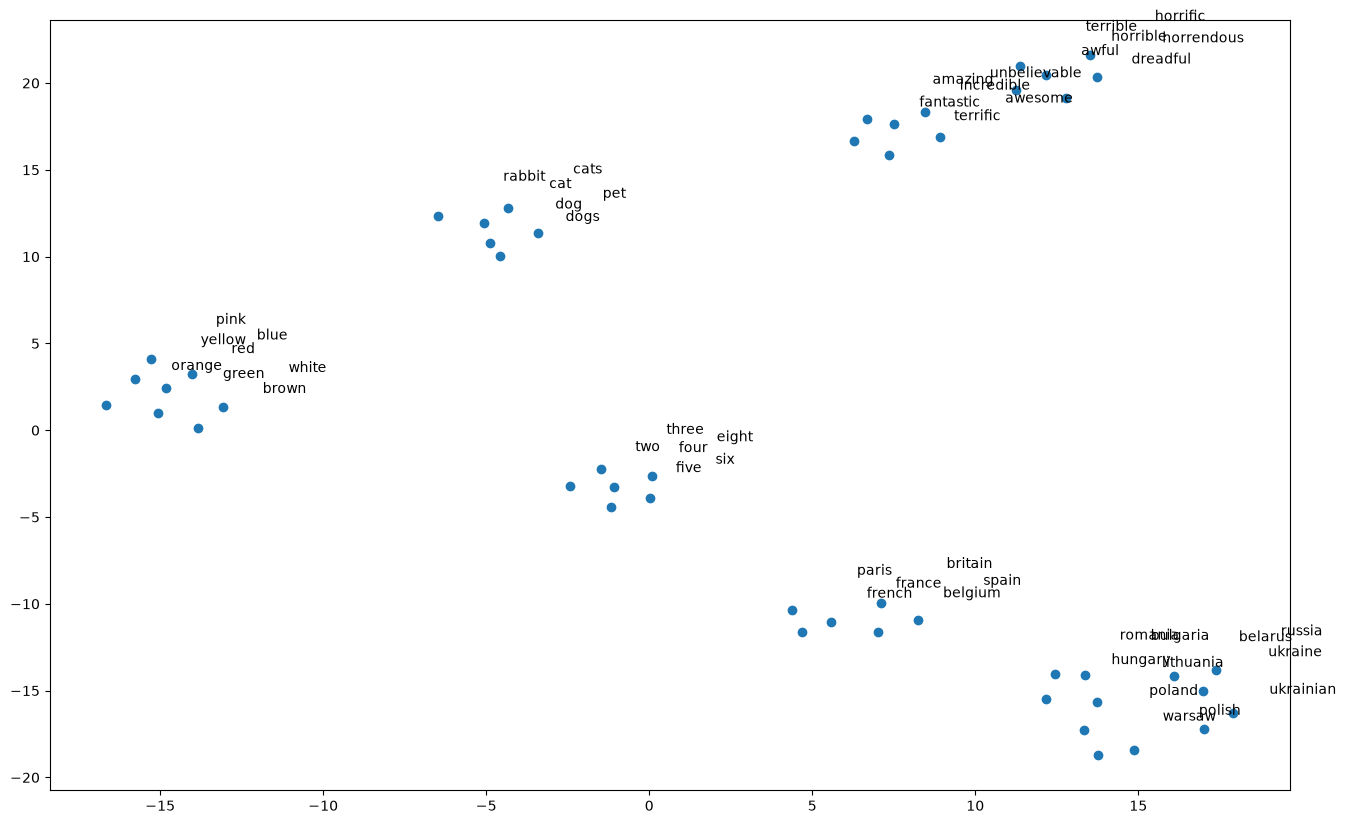

In [38]:
plot_word_embeddings(glove, ["awesome", "terrible", "ukraine", "poland", "france", "red", "green", "cat", "two"])

# Векторна арифметика

Ми можемо додавати та віднімати вектори слів. Результат таких операцій (який теж буде вектором) можна перетворити назад в слово. Для цього знайдемо кілька найближчих до результата векторів і подивимося, які слова їм відповідають.

Векторну аріфметику використовують для пошуку слів за аналогіями. Класичний приклад з першої статті про Word2Vec виглядає так:

```
V("king") - V("man") + V("woman") ~= V("queen")
```

In [39]:
glove.similar_by_vector(glove["king"] - glove["man"] + glove["woman"])

[('king', 0.8209066987037659),
 ('queen', 0.7119165658950806),
 ('princess', 0.6121214628219604),
 ('monarch', 0.6024806499481201),
 ('prince', 0.596004068851471),
 ('throne', 0.5915313363075256),
 ('daughter', 0.5588055849075317),
 ('elizabeth', 0.554740309715271),
 ('kingdom', 0.5494517087936401),
 ('mother', 0.5419816970825195)]

### Завдання

Знайдіть найближчий вектор виразу
`paris` - `france` + `ukraine`

In [40]:
answer = glove.similar_by_vector(glove["paris"] - glove["france"] + glove["ukraine"])
lab.answer(answer)   # мені теж не подобається те, як написана відповідь :)

Відповідь правильна ✅
Так, вірно! 💪


[('kiev', 0.7856265306472778),
 ('ukraine', 0.7307591438293457),
 ('moscow', 0.6962895393371582),
 ('ukrainian', 0.6085987091064453),
 ('baku', 0.567898690700531),
 ('russia', 0.5644105076789856),
 ('helsinki', 0.5639599561691284),
 ('tbilisi', 0.561897873878479),
 ('minsk', 0.5441251993179321),
 ('yushchenko', 0.5439420342445374)]

# Готово!

На наступному занятті ми:
- Використаємо ембедінги слів для класифікації текстів
- Дізнаємося, як влаштований word2vec
- Напишемо свою імплементацію word2vec
- Подивимося, як обійти проблему несловникових токенів
